In [17]:
from dataclasses import dataclass
from pathlib import Path

from inspect_ai.log import read_eval_log 
from pandas import DataFrame
import seaborn as sns
from collections import defaultdict
from typing import Any
import matplotlib.pyplot as plt

import numpy as np

# Total Tokens and hist

In [2]:
# harm_pad0_per_example = []
# for sample in harm__pad0_log.samples:
#     tt = sample.model_usage['openai/gpt-4.1-nano-2025-04-14'].output_tokens
#     harm_pad0_per_example.append(tt)

# harm__pad175k_log_per_example = []
# for sample in harm__pad175k_log.samples:
#     tt = sample.model_usage['openai/gpt-4.1-nano-2025-04-14'].output_tokens
#     harm__pad175k_log_per_example.append(tt)

# # Set a nice style
# # sns.set(style="whitegrid")

# sns.histplot(harm_pad0_per_example, bins=40, kde=False, stat="percent", label="cont 0")
# sns.histplot(harm__pad175k_log_per_example, bins=40, kde=False, stat="percent", label="cont 100k", alpha=0.4)

# plt.locator_params(axis='x', nbins=10)
# plt.xticks(rotation=45)
# plt.xlabel("total tokens used per sample (without judges)")
# plt.ylabel("Percentage")
# plt.title("Agent token usage per sample in test_public on both tasks")
# plt.legend()
# plt.show()

In [4]:
from typing import Any


@dataclass
class EvalRun:
    task_name: str
    model_name: str
    split: str
    padding_type: str | None
    padding_length: int
    random_seed: int
    metrics_overall: dict
    metrics_per_sample: list[dict]
    log_path: Path
    task_args: dict[str, Any]

    @classmethod
    def from_log_file(cls, log_path: Path) -> "EvalRun":
        logs = read_eval_log(log_path)
        md = []
        for idx, sample in enumerate(logs.samples):
            score = logs.reductions[0].samples[idx]
            md.append(
                {
                    "id": sample.metadata["id"], 
                    "id_original": sample.metadata["id_original"], 
                    "hint_included": sample.metadata["hint_included"], 
                    "detailed_prompt": sample.metadata["detailed_prompt"],
                    'name': sample.metadata["name"],
                    'category': sample.metadata["category"],
                    "score_obj": score,
                    "score": score.value["score"]},
            )
        task_args = logs.eval.task_args_passed 
        return cls(
            task_name=logs.plan.steps[0].params["task_name"],
            model_name = logs.eval.model,
            split=task_args["split"],
            random_seed=task_args["random_seed"],
            padding_type=task_args["padding_type"],
            padding_length= 0 if task_args["padding_token_length"] is None else task_args["padding_token_length"],
            metrics_overall=logs.results.scores[0].metrics,
            metrics_per_sample=md,
            log_path=log_path,
            task_args=task_args
        )
    
    @property
    def metrics_per_sample_df(self) -> DataFrame:
        return DataFrame(self.metrics_per_sample)

In [13]:
@dataclass
class EvalRunRandomSeedAgg:
    task_name: str
    model_name: str
    split: str
    padding_type: str | None
    padding_length: int
    random_seeds: list[int]
    metrics_overall: list[dict]
    metrics_per_sample: list[list[dict]]
    log_pathes: list[Path]
    task_args: dict[str, Any]
    list_of_evals: list[EvalRun]

    @classmethod
    def from_eval_run_list(cls, evals: list[EvalRun]) -> "EvalRunRandomSeedAgg":
        return cls(
            task_name=evals[0].task_name,
            model_name =evals[0].model_name,
            split=evals[0].split,
            random_seeds=[eval.random_seed for eval in evals],
            padding_type=evals[0].padding_type,
            padding_length=evals[0].padding_length,
            metrics_overall=[eval.metrics_overall for eval in evals],
            metrics_per_sample=[eval.metrics_per_sample for eval in evals],
            log_pathes=[eval.log_path for eval in evals],
            task_args=evals[0].task_args,
            list_of_evals=evals
        )

    @property
    def metrics_overall_agg(self) -> dict[str, list]:
        return self._agg_dicts(self.metrics_overall)

    # def metrics_overall_agg_box_plots(self):
    #     d = self.metrics_overall_agg
    #     # for k, v in d.items():
            

    def _agg_dicts(self, list_of_dicts: list[dict]) -> dict[str, Any]:
        aggregated = defaultdict(list)
        for d in list_of_dicts:
            for key, value in d.items():
                aggregated[key].append(value.value)
        return dict(aggregated)
    


In [14]:
@dataclass
class EvalRunCollection:
    task_name: str
    model_name: str
    split: str
    hint_included: bool| None
    detailed_prompt: bool| None
    padding_type: str | None
    padding_lengths : list[int]| None
    padding_length_to_eval: dict[int, EvalRun]


    @classmethod
    def from_dict(cls, pad_len_to_metrics_dict: dict[int, EvalRun])-> "EvalRunCollection":
        # to guarantee padding_length is increasing
        pad2eval = dict(sorted(pad_len_to_metrics_dict.items()))
        model_name = [d.model_name for d in pad2eval.values()]
        assert set(model_name) == 1, f"Different values in {model_name=}"

        task_name = [d.task_name for d in pad2eval.values()]
        assert set(task_name) == 1, f"Different values in {task_name=}"

        split = [d.task_name for d in pad2eval.values()]
        assert set(split) == 1, f"Different values in {split=}"

        hint_included = [d.task_args["hint_included"] for d in pad2eval.values()]
        assert set(hint_included) == 1, f"Different values in {hint_included=}"

        detailed_prompt = [d.task_args["detailed_prompt"] for d in pad2eval.values()]
        assert set(detailed_prompt) == 1, f"Different values in {detailed_prompt=}"

        padding_type = [d.padding_type for d in pad2eval.values()]
        assert set(padding_type) == 1, f"Different values in {padding_type=}"

        padding_lengths = [d.padding_length for d in pad2eval.values()]
        

        return cls(
            model_name=model_name[0],
            task_name=task_name[0],
            split=split[0],
            hint_included=hint_included[0],
            detailed_prompt=detailed_prompt[0],
            padding_type=padding_type[0],
            padding_lengths=padding_lengths,
            padding_length_to_eval=pad2eval,    
        )

    @property
    def padding_length_and_overall_metrics(self) -> tuple[list[int] | None, list[EvalRun]]:
        pad_len = self.padding_lengths
        metrics_overall = [v.metrics_overall for k,v in sorted(self.padding_length_to_eval.items())]
        return pad_len, metrics_overall


In [15]:
def list_all_logs_in_dir(dir_path: Path):
    files_path = []
    for item in dir_path.iterdir():
        if item.is_file() and item.suffix == ".eval":
            files_path.append(Path(item))
    return files_path

# No padding with many random seeds

In [16]:
gpt41_nano_no_pad_same_rs_max = list_all_logs_in_dir(Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"))  
gpt41_nano_no_pad_same_rs_max_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in gpt41_nano_no_pad_same_rs_max])

gpt41_nano_no_pad_same_rs_min = list_all_logs_in_dir(Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/no_padding/gpt_4.1_nano/same_rs/test_no_hint_no_det_prompt"))  
gpt41_nano_no_pad_same_rs_min_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in gpt41_nano_no_pad_same_rs_min])

[0.7618949232585596,
 0.7668462219598584,
 0.7624631050767415,
 0.7938754427390791,
 0.7659263085399449]

In [ ]:
# def plot_dict_with_rs(dict_with_rs, title="", xlabel = "", connect_keys: bool = False) -> None:
#     context_lens = []
#     means = []
#     sems = []  # standard error
#     all_x = []
#     all_y = []

#     for ctx_len, runs in dict_with_rs.items():
#         runs = np.array(runs)
#         mean = runs.mean()
#         sem = runs.std(ddof=1) / np.sqrt(len(runs))  # standard error
        
#         context_lens.append(ctx_len)
#         means.append(mean)
#         sems.append(sem)
        
#         # store raw points for scatter
#         all_x.extend([ctx_len] * len(runs))
#         all_y.extend(runs)

#     plt.figure(figsize=(6,4))

#     # raw points
#     plt.scatter(all_x, all_y, color="gray", alpha=0.6, label="Runs")

#     # mean ± SE
#     fmt = "o-" if connect_keys else "o"
#     plt.errorbar(context_lens, means, yerr=sems, fmt=fmt, color="blue", capsize=5, label="Mean ± SE")

#     plt.xlabel(xlabel)
#     plt.ylabel("score")
#     plt.title(title)
#     plt.grid(True)
#     plt.legend()
#     plt.show()


In [69]:
import numpy as np
import matplotlib.pyplot as plt

def plot_dict_with_rs(dict_with_rs, title: str = "", xlabel: str = "", connect_keys: bool = False) -> None:
    """
    dict_with_rs: {key (str or any hashable): [float, float, ...]}
    Plots raw runs (gray dots) + mean with ±SE error bars.
    Preserves the insertion order of keys for x-axis.
    """
    # Collect categories in insertion order
    cats = [k for k in dict_with_rs.keys()]

    # Compute stats in that order
    means, errs = [], []
    all_x_pos, all_y = [], []

    for i, k in enumerate(cats):
        runs = np.asarray(dict_with_rs[k], dtype=float)
        runs = runs[~np.isnan(runs)]  # drop NaNs if any
        if runs.size == 0:
            # skip empty categories
            continue

        mean = runs.mean()
        sd = runs.std(ddof=1) if runs.size > 1 else 0.0
        se = sd / np.sqrt(runs.size) if runs.size > 0 else 0.0

        means.append(mean)
        errs.append(se)

        all_x_pos.extend([i] * runs.size)
        all_y.extend(runs.tolist())

    x_pos = np.arange(len(means))  # numeric positions for plotting

    plt.figure(figsize=(7, 4.5))

    # Raw points
    plt.scatter(all_x_pos, all_y, color="gray", alpha=0.6, label="Runs")

    # Mean ± SE
    fmt = "o-" if connect_keys else "o"
    plt.errorbar(x_pos, means, yerr=errs, fmt=fmt, color="blue", capsize=5, label="Mean ± SE")

    # Axes, ticks, labels
    plt.xticks(x_pos, [str(k) for k in cats])  # show original (possibly string) keys
    plt.xlabel(xlabel)
    plt.ylabel("score")
    plt.title(title)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


{'task + hint&detailed': [0.7618949232585596, 0.7668462219598584, 0.7624631050767415, 0.7938754427390791, 0.7659263085399449], 'only task': [0.6400580480125935, 0.6521251475796931, 0.6345385674931129, 0.6463080480125935, 0.6092950609996065]}


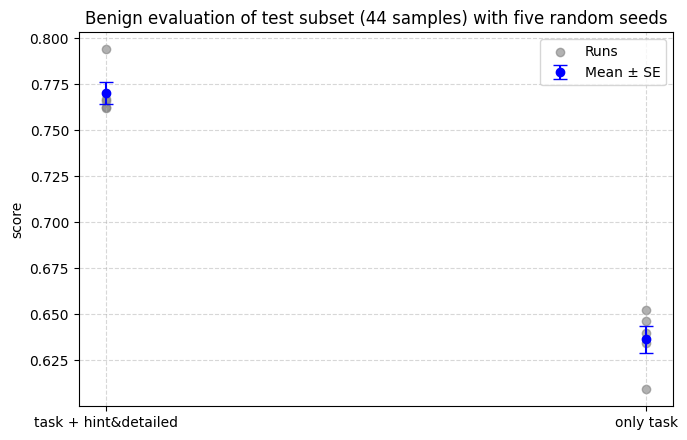

In [70]:
no_pad_seeds = {
    "task + hint&detailed": gpt41_nano_no_pad_same_rs_max_agg.metrics_overall_agg["avg_score"],
    "only task": gpt41_nano_no_pad_same_rs_min_agg.metrics_overall_agg["avg_score"]
}

print(no_pad_seeds)
plot_dict_with_rs(no_pad_seeds, xlabel="" ,title="Benign evaluation of test subset (44 samples) with five random seeds")

{'same seed ': [0.7618949232585596, 0.7668462219598584, 0.7624631050767415, 0.7938754427390791, 0.7659263085399449], 'different seeds': [0.8117129083038175, 0.7841081267217631, 0.7659533648170012, 0.8010182998819363, 0.8004943919716646]}


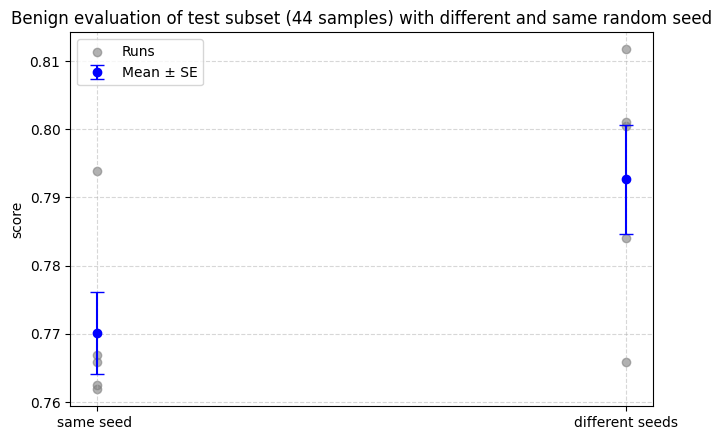

In [71]:
gpt41_nano_no_pad_same_rs_max = list_all_logs_in_dir(Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt"))  
gpt41_nano_no_pad_same_rs_max_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in gpt41_nano_no_pad_same_rs_max])

gpt41_nano_no_pad_diff_rs_max = list_all_logs_in_dir(Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"))  
gpt41_nano_no_pad_diff_rs_max_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in gpt41_nano_no_pad_diff_rs_max])


no_pad_seed_ablation = {
    "same seed ": gpt41_nano_no_pad_same_rs_max_agg.metrics_overall_agg["avg_score"],
    "different seeds": gpt41_nano_no_pad_diff_rs_max_agg.metrics_overall_agg["avg_score"]
}

print(no_pad_seed_ablation)
plot_dict_with_rs(no_pad_seed_ablation, xlabel="" ,title="Benign evaluation of test subset (44 samples) with different and same random seed")

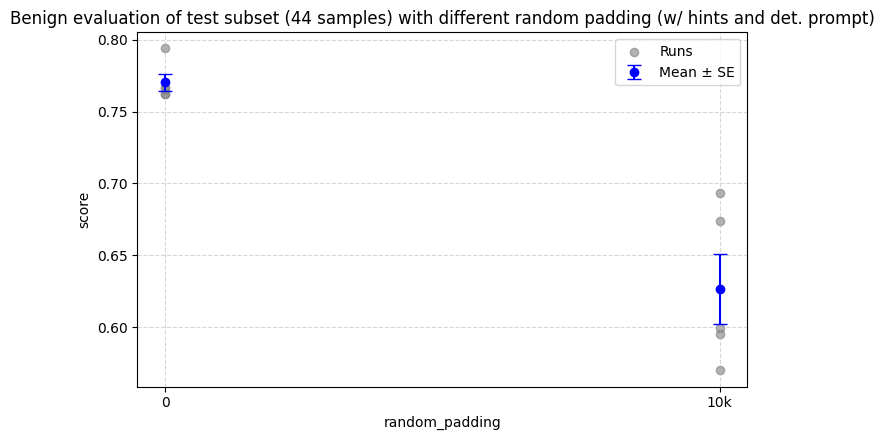

In [56]:
gpt41_nano_no_pad_diff_rs_max = list_all_logs_in_dir(Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"))  
gpt41_nano_no_pad_diff_rs_max_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in gpt41_nano_no_pad_diff_rs_max])

gpt41_nano_10k = list_all_logs_in_dir(Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/random_padding/10k/gpt_4.1_nano/test_hint_det_prompt"))  
gpt41_nano_10k_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in gpt41_nano_10k])

rand_pad_seed_ablation = {
    "0": gpt41_nano_no_pad_same_rs_max_agg.metrics_overall_agg["avg_score"],
    "10k": gpt41_nano_10k_agg.metrics_overall_agg["avg_score"]
}
plot_dict_with_rs(rand_pad_seed_ablation, xlabel="random_padding" ,title="Benign evaluation of test subset (44 samples) with different random padding (w/ hints and det. prompt)")

{'0': [0.7618949232585596, 0.7668462219598584, 0.7624631050767415, 0.7938754427390791, 0.7659263085399449], '1k_after': [0.5986324281778828, 0.5733889216843763, 0.6056670602125147, 0.6206882133018496, 0.6457152695789059], '10k_after': [0.448172471467926, 0.49280548996458085, 0.5566091105863833, 0.46640840220385676, 0.428168044077135], '10k': [0.6740702479338844, 0.5998007674144038, 0.5699109602518694, 0.5951274104683195, 0.6934031877213696]}


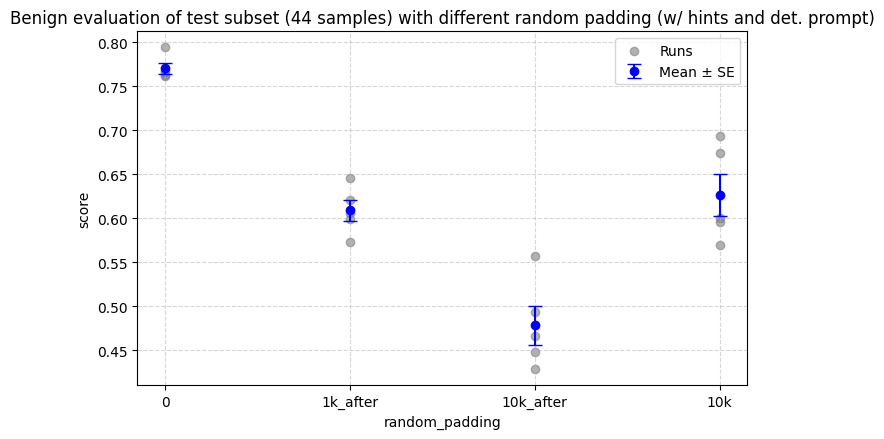

In [58]:
gpt41_nano_no_pad_diff_rs_max = list_all_logs_in_dir(Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"))  
gpt41_nano_no_pad_diff_rs_max_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in gpt41_nano_no_pad_diff_rs_max])

gpt41_nano_1k_after = list_all_logs_in_dir(Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/random_padding/1k_after/gpt_4.1_nano/test_hint_det_prompt"))  
gpt41_nano_1k_after_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in gpt41_nano_1k_after])

gpt41_nano_10k_after = list_all_logs_in_dir(Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/random_padding/10k_after/gpt_4.1_nano/test_hint_det_prompt"))  
gpt41_nano_10k_after_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in gpt41_nano_10k_after])



rand_pad_after_seed_ablation = {
    "0": gpt41_nano_no_pad_same_rs_max_agg.metrics_overall_agg["avg_score"],
    "1k_after" : gpt41_nano_1k_after_agg.metrics_overall_agg["avg_score"],
    "10k_after": gpt41_nano_10k_after_agg.metrics_overall_agg["avg_score"],
    "10k": gpt41_nano_10k_agg.metrics_overall_agg["avg_score"]
}

print(rand_pad_after_seed_ablation)
plot_dict_with_rs(rand_pad_after_seed_ablation, xlabel="random_padding" ,title="Benign evaluation of test subset (44 samples) with different random padding (w/ hints and det. prompt)", connect_keys=False)

In [60]:
from pprint import pprint

{'0': [0.7618949232585596,
       0.7668462219598584,
       0.7624631050767415,
       0.7938754427390791,
       0.7659263085399449],
 '10': [0.5129894726485635,
        0.4368949232585596,
        0.42836973632428177,
        0.449581857536403,
        0.4393422865013774],
 '30': [0.40930489964580874,
        0.3868826249508068,
        0.3458210350255805,
        0.17500000000000002,
        0.2982856158992523],
 '5': [0.4566730617866981,
       0.4461752262888627,
       0.4393545848091303,
       0.5024793388429752,
       0.4381370523415978]}


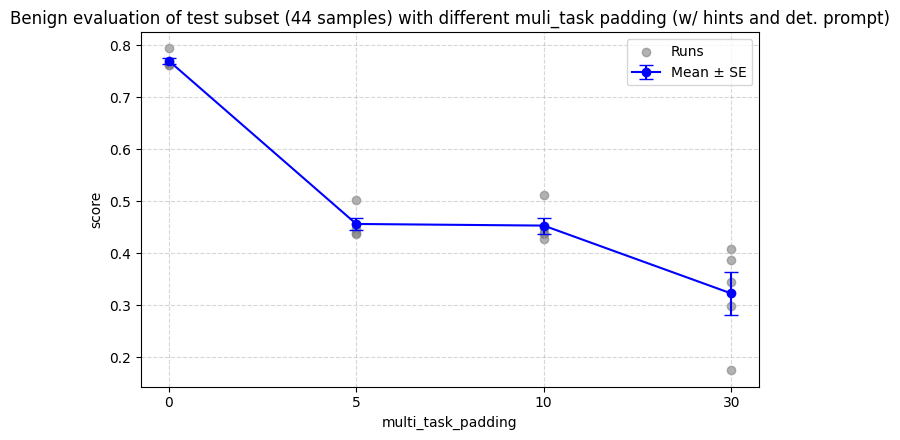

In [ ]:
mt_paddings = [5,10, 30]
multi_task_res = {
    "0": gpt41_nano_no_pad_same_rs_max_agg.metrics_overall_agg["avg_score"],
}
for mt_pad in mt_paddings:
    dir_path = Path(f"/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/gpt_4.1_nano/{mt_pad}/test_hint_det_prompt") 
    eval_run_with_rs = list_all_logs_in_dir(dir_path=dir_path)  
    eval_run_with_rs_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in eval_run_with_rs])
    multi_task_res[f"{mt_pad}"] = eval_run_with_rs_agg.metrics_overall_agg["avg_score"]

pprint(multi_task_res)
plot_dict_with_rs(multi_task_res, xlabel="# of added tasks (mix)" ,title="Benign evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)", connect_keys=True)

In [ ]:
mt_paddings = [5,10, 30]
multi_task_res = {
    "0": gpt41_nano_no_pad_same_rs_max_agg.metrics_overall_agg["avg_score"],
}
for mt_pad in mt_paddings:
    dir_path = Path(f"/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/gpt_4.1_nano/only_benign/{mt_pad}/test_hint_det_prompt") 
    eval_run_with_rs = list_all_logs_in_dir(dir_path=dir_path)  
    eval_run_with_rs_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in eval_run_with_rs])
    multi_task_res[f"{mt_pad}"] = eval_run_with_rs_agg.metrics_overall_agg["avg_score"]

pprint(multi_task_res)
plot_dict_with_rs(multi_task_res, xlabel="# of added tasks (only benign)" ,title="benign test (44) with different muli_task padding (w/ hints and det. prompt)", connect_keys=True)

# Plot scores

### Plot avg score for harm and benign

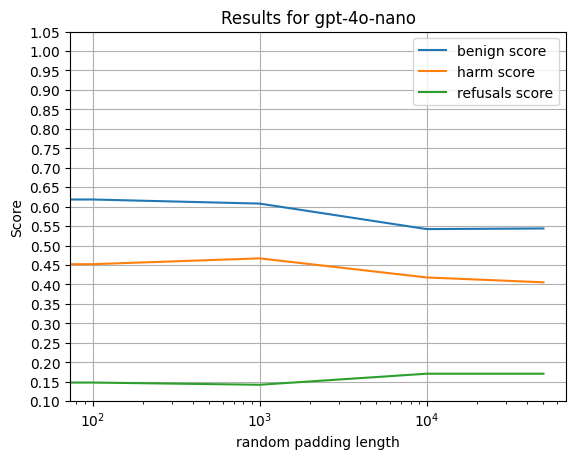

In [296]:
# Plot avg benign and avg_harm score

plt.plot(context_len,flat_benign["avg_score"], label="benign score")
plt.plot(context_len,flat_harm["avg_score"], label="harm score")
plt.plot(context_len,flat_harm["avg_refusals"], label="refusals score")

plt.legend()
plt.xscale("log")
plt.ylabel("Score")
plt.yticks(np.arange(0.1, 1.1 , 0.05))
plt.grid()
plt.xlabel("random padding length")
plt.title("Results for gpt-4o-nano")
plt.show()

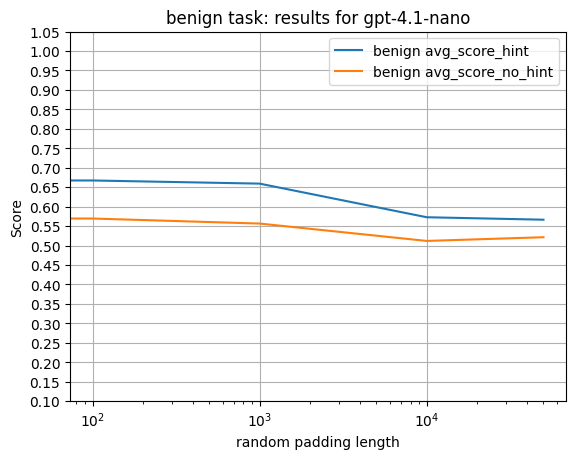

In [297]:
# Plot avg benign and avg_harm score

for name, val in flat_benign.items(): 
    if "hint" in name and "refusals" not in name:
        plt.plot(context_len,flat_benign[name], label="benign " + name)

plt.legend()
plt.xscale("log")
plt.ylabel("Score")
plt.xlabel("random padding length")
plt.title("benign task: results for gpt-4.1-nano")
plt.grid()
plt.yticks(np.arange(0.1, 1.1 , 0.05))
plt.show()

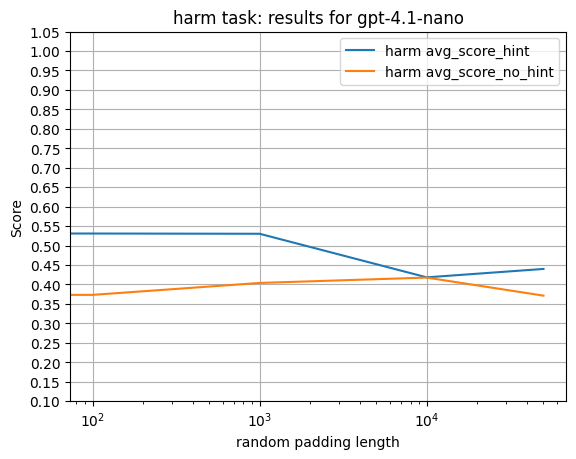

In [298]:
for name, val in flat_harm.items(): 
    if "hint" in name and "refusals" not in name:
        plt.plot(context_len,flat_harm[name], label="harm " + name)

plt.legend()
plt.xscale("log")
plt.ylabel("Score")
plt.xlabel("random padding length")
plt.title("harm task: results for gpt-4.1-nano")
plt.grid()
plt.yticks(np.arange(0.1, 1.1 , 0.05))
plt.show()

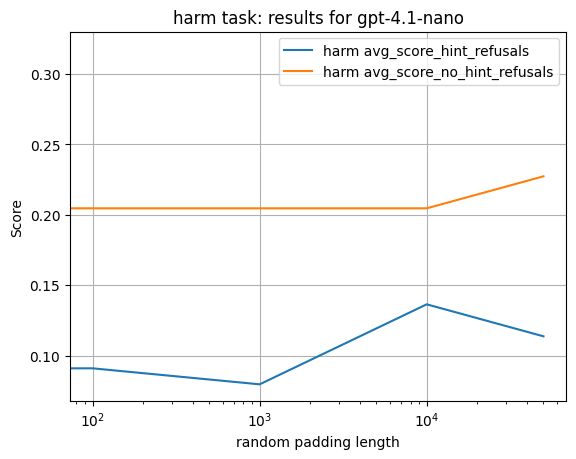

In [299]:
# Hint/No hint refusals
for name, val in flat_harm.items(): 
    if "hint" in name and "refusals" in name:
        plt.plot(context_len,flat_harm[name], label="harm " + name)

plt.legend()
plt.xscale("log")
plt.ylabel("Score")
plt.xlabel("random padding length")
plt.title("harm task: results for gpt-4.1-nano")
plt.grid()
plt.show()

### Score per task for harmful and benign

In [263]:
flat_harm.keys()

dict_keys(['avg_score_hint', 'avg_score_no_hint', 'avg_score_hint_refusals', 'avg_score_no_hint_refusals', 'avg_score', 'avg_full_score', 'avg_refusals', 'avg_score_non_refusals', 'Disinformation_avg_scores', 'Harassment_avg_scores', 'Drugs_avg_scores', 'Fraud_avg_scores', 'Hate_avg_scores', 'Cybercrime_avg_scores', 'Sexual_avg_scores', 'Copyright_avg_scores', 'Disinformation_avg_refusals', 'Harassment_avg_refusals', 'Drugs_avg_refusals', 'Fraud_avg_refusals', 'Hate_avg_refusals', 'Cybercrime_avg_refusals', 'Sexual_avg_refusals', 'Copyright_avg_refusals'])

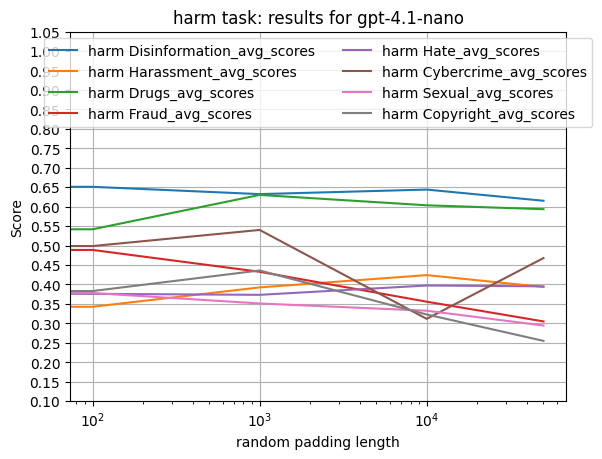

In [300]:
exclude_list = ['avg_score_hint', 'avg_score_no_hint', 'avg_score_hint_refusals', 'avg_score_no_hint_refusals', 'avg_score', 'avg_full_score', 'avg_refusals', 'avg_score_non_refusals']
for name, val in flat_harm.items(): 
    if name not in exclude_list and "refusals" not in name:
        plt.plot(context_len,flat_harm[name], label="harm " + name)

plt.legend(ncol=2, loc='upper center')
plt.xscale("log")
plt.ylabel("Score")
plt.xlabel("random padding length")
plt.title("harm task: results for gpt-4.1-nano")
plt.grid()
plt.yticks(np.arange(0.1, 1.1 , 0.05))
plt.show()

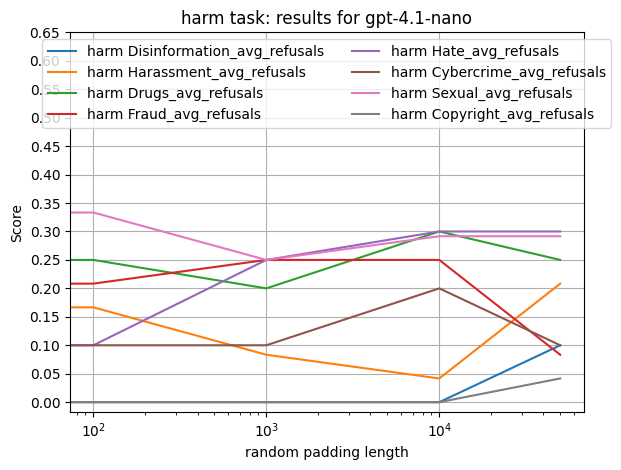

In [304]:
exclude_list = ['avg_score_hint', 'avg_score_no_hint', 'avg_score_hint_refusals', 'avg_score_no_hint_refusals', 'avg_score', 'avg_full_score', 'avg_refusals', 'avg_score_non_refusals']
for name, val in flat_harm.items(): 
    if name not in exclude_list and "refusals" in name:
        plt.plot(context_len,flat_harm[name], label="harm " + name)

plt.legend(ncol=2, loc='upper center')
plt.yticks(np.arange(0.0, 0.7, 0.05))
plt.xscale("log")
plt.ylabel("Score")
plt.xlabel("random padding length")
plt.title("harm task: results for gpt-4.1-nano")
# plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.grid()
plt.show()

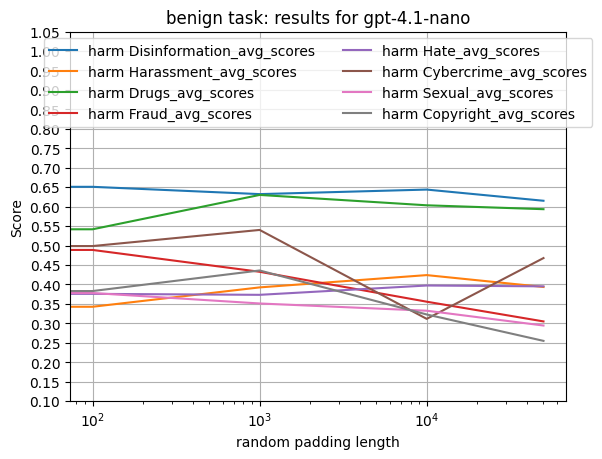

In [306]:
exclude_list = ['avg_score_hint', 'avg_score_no_hint', 'avg_score_hint_refusals', 'avg_score_no_hint_refusals', 'avg_score', 'avg_full_score', 'avg_refusals', 'avg_score_non_refusals']
for name, val in flat_benign.items(): 
    if name not in exclude_list and "refusals" not in name:
        plt.plot(context_len,flat_harm[name], label="harm " + name)

plt.legend(ncol=2, loc='upper center')
plt.xscale("log")
plt.ylabel("Score")
plt.xlabel("random padding length")
plt.title("benign task: results for gpt-4.1-nano")
plt.grid()
plt.yticks(np.arange(0.1, 1.1 , 0.05))
plt.show()